# Email Campaign A/B/C Test Analysis (Hillstrom)

## 1. Problem Statement

### Context
An online clothing retailer ran an email marketing experiment. 64,000 customers who had
purchased within the last 12 months were randomly split into three groups of about 21,300 each:
- **Mens E-Mail** — received an email featuring men's merchandise;
- **Womens E-Mail** — received an email featuring women's merchandise;
- **No E-Mail** — received no email (control group).

For two weeks after the campaign, the retailer tracked whether each customer visited the website,
made a purchase, and how much they spent.

### Business Question
Should the company send the email campaign, and if so, which version: men's or women's?

### Metrics
| Metric | Formula | Role |
|---|---|---|
| Purchase conversion rate | customers who purchased / all customers in the group | **primary** |
| Visit rate | customers who visited the website / all customers in the group | secondary |
| Revenue per customer | total spend in the group / all customers in the group | secondary |

**Why conversion is the primary metric:** the business earns money from purchases, not visits.
Revenue matters, but most customers spend $0, so the variance is high and a test on revenue
is less sensitive. The decision is based on conversion; revenue is analyzed as a supporting metric.

### Hypotheses
p_M, p_W, p_C — purchase conversion rate in the whole customer population with the men's email,
the women's email, and no email.

| Comparison | H₀ | H₁ |
|---|---|---|
| Men's vs Control | p_M = p_C | p_M ≠ p_C |
| Women's vs Control | p_W = p_C | p_W ≠ p_C |
| Men's vs Women's | p_M = p_W | p_M ≠ p_W |

### Significance Level
- α = 0.05, number of comparisons m = 3.
- Bonferroni correction: threshold for each comparison α / m = 0.05 / 3 ≈ **0.0167**.
  Without the correction, the chance of at least one false positive would be 1 − 0.95³ ≈ 14%.
- **Two-sided** tests: an email can either increase or decrease conversion,
  and when comparing the two emails we do not know in advance which one is better.

### Analysis Plan
1. Data quality check
2. Descriptive statistics
3. Randomization check (SRM, group balance)
4. Test power (MDE)
5. Proportion tests: conversion and visits
6. Revenue tests: t-test, bootstrap, Mann–Whitney
7. Segment analysis: which customers respond to which email
8. Business conclusion and recommendation

## 2. Data Quality Check

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

In [2]:
df = pd.read_csv('../data/hillstrom.csv')

In [3]:
df.shape

(64000, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


In [5]:
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [6]:
df['recency'].between(1, 12).all() # should be 1-12 (months in year)

np.True_

In [7]:
df[(df['history'] < 0) | (df['spend'] < 0)]['recency'].count()

np.int64(0)

In [8]:
for col in ['mens', 'womens', 'newbie', 'visit', 'conversion']:
    print(col, df[col].isin([0, 1]).all())

mens True
womens True
newbie True
visit True
conversion True


In [9]:
for col in ['segment', 'zip_code', 'channel', 'history_segment']:
    print(col, list(df[col].unique()))

segment ['Womens E-Mail', 'No E-Mail', 'Mens E-Mail']
zip_code ['Surburban', 'Rural', 'Urban']
channel ['Phone', 'Web', 'Multichannel']
history_segment ['2) $100 - $200', '3) $200 - $350', '5) $500 - $750', '1) $0 - $100', '6) $750 - $1,000', '4) $350 - $500', '7) $1,000 +']


In [10]:
len(df[(df['spend'] > 0) & (df['conversion'] == 0)])

0

In [11]:
len(df[(df['spend'] == 0) & (df['conversion'] == 1)])

0

In [12]:
len(df[(df['visit'] == 0) & (df['conversion'] == 1)])

0

In [13]:
df.duplicated().sum()

np.int64(6562)

### Conclusion
- The dataset has **64,000 rows and 12 columns**; data types are correct and there are **no missing values**.
- All values are within valid ranges: `recency` is 1–12, `history` and `spend` are non-negative,
  binary columns contain only 0 and 1.
- Categorical columns have no unexpected values. Note: `zip_code` contains the typo `Surburban`
  (instead of *Suburban*) in the original data; it is kept as is.
- The data is logically consistent: `spend > 0` exactly when `conversion = 1`,
  and there are no purchases without a website visit.
- **6,562 rows are exact duplicates.** Since there is no customer ID and each row represents
  a separate customer, these are different customers with identical attributes, so they are kept.

**The data is clean and ready for analysis.**

## 3. Descriptive Statistics

In [14]:
grouped_segment = df.groupby('segment').agg(
    customers=('segment', 'count'),
    visit_rate=('visit', 'mean'),
    conversion_rate=('conversion', 'mean'),
    revenue_per_customer=('spend', 'mean')
)
grouped_segment.round(4)

,customers,visit_rate,conversion_rate,revenue_per_customer
segment,,,,
Mens E-Mail,21307,0.1828,0.0125,1.4226
No E-Mail,21306,0.1062,0.0057,0.6528
Womens E-Mail,21387,0.1514,0.0088,1.0772


In [15]:
print(f'{((df['spend'] == 0).mean() * 100).round(2)} per cent of users spent $0')

99.1 per cent of users spent $0


In [16]:
(df['spend']).mode()[0]

np.float64(0.0)

In [17]:
grouped_segment_spend = df.groupby('segment').agg(
    customers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_spend.round(4)

,customers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,21307,1.4226,0.0,0.0,0.0,0.0,29.99
No E-Mail,21306,0.6528,0.0,0.0,0.0,0.0,0.00
Womens E-Mail,21387,1.0772,0.0,0.0,0.0,0.0,0.00


In [18]:
buyers = df[df['spend'] > 0]

In [19]:
grouped_segment_buyers = buyers.groupby('segment').agg(
    buyers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_buyers.round(2)

,buyers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,267,113.53,29.99,66.98,152.72,262.79,499.00
No E-Mail,122,114.00,35.04,88.36,146.17,226.88,487.64
Womens E-Mail,189,121.89,35.20,94.71,163.79,268.04,499.00


In [37]:
buyers[buyers['segment'] == 'Mens E-Mail'].groupby('spend').agg(
    buyers=('spend', 'count')
)

,buyers
spend,
29.99,70
30.24,1
30.94,1
30.98,1
32.17,1
...,...
397.32,1
421.17,1
421.76,1


In [20]:
grouped_segment_history = df.groupby('segment').agg(
    avg=('history', 'mean'),
    q25=('history', lambda x: x.quantile(0.25)),
    q50=('history', lambda x: x.quantile(0.50)),
    q75=('history', lambda x: x.quantile(0.75)),
    q90=('history', lambda x: x.quantile(0.90)),
    q99=('history', lambda x: x.quantile(0.99)),
)
grouped_segment_history.round(2)

,avg,q25,q50,q75,q90,q99
segment,,,,,,
Mens E-Mail,242.84,63.58,157.22,325.22,563.63,1229.96
No E-Mail,240.88,65.30,156.66,325.17,561.06,1191.89
Womens E-Mail,242.54,65.04,160.09,326.82,558.16,1239.73


In [21]:
crosstab_channel = pd.crosstab(df['segment'], df['channel'], normalize='index')

crosstab_channel.round(4)

channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,0.1209,0.4337,0.4454
No E-Mail,0.1223,0.4378,0.4399
Womens E-Mail,0.1206,0.4420,0.4374


In [22]:
crosstab_zip_code = pd.crosstab(df['segment'], df['zip_code'], normalize='index')

crosstab_zip_code.round(4)

zip_code,Rural,Surburban,Urban
segment,,,
Mens E-Mail,0.1522,0.4459,0.4019
No E-Mail,0.1473,0.4518,0.4009
Womens E-Mail,0.1487,0.4512,0.4001


In [23]:
crosstab_history_segment = pd.crosstab(df['segment'], df['history_segment'], normalize='index')

crosstab_history_segment.round(4)

history_segment,1) $0 - $100,2) $100 - $200,3) $200 - $350,4) $350 - $500,5) $500 - $750,"6) $750 - $1,000","7) $1,000 +"
segment,,,,,,,
Mens E-Mail,0.3625,0.2202,0.1920,0.0984,0.0750,0.0302,0.0218
No E-Mail,0.3573,0.2270,0.1898,0.0997,0.0775,0.0292,0.0195
Womens E-Mail,0.3569,0.2210,0.1943,0.1023,0.0777,0.0277,0.0200


In [24]:
crosstab_newbie = pd.crosstab(df['segment'], df['newbie'], normalize='index')

crosstab_newbie.round(4)

newbie,0,1
segment,,
Mens E-Mail,0.4985,0.5015
No E-Mail,0.4980,0.5020
Womens E-Mail,0.4968,0.5032


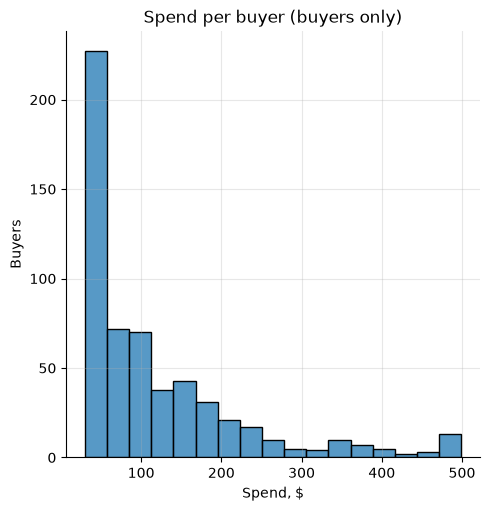

In [25]:
sns.displot(data=buyers, x='spend')
plt.title('Spend per buyer (buyers only)')
plt.xlabel('Spend, $')
plt.ylabel('Buyers')
plt.grid(axis='both', alpha=0.3)
plt.show()

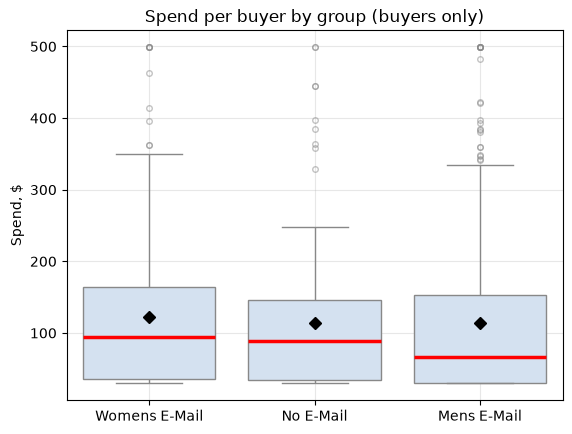

In [26]:
sns.boxplot(data=buyers, x='segment', y='spend', 
            color='#cfe0f5',
            medianprops=dict(color='red', linewidth=2.5),
            flierprops=dict(marker='o', markersize=4, alpha=0.5),
            showmeans=True,
            meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=6)
           )
plt.title('Spend per buyer by group (buyers only)')
plt.xlabel('')
plt.ylabel('Spend, $')
plt.grid(axis='both', alpha=0.3)
plt.show()

### Conclusion

**Metrics by group** (descriptive only, significance is tested in step 6):

| Group | Visit rate | Conversion rate | Revenue per customer |
|---|---|---|---|
| Mens E-Mail | 18.3% | 1.25% | \$1.42 |
| Womens E-Mail | 15.1% | 0.88% | \$1.08 |
| No E-Mail | 10.6% | 0.57% | \$0.65 |

Both emails show higher values than the control group; the men's email is the highest on all three metrics.

- **99.1% of customers made no purchase** during the test: the mode of `spend` is 0
  and all percentiles up to the 90th are 0.
- **578 customers made a purchase.** Their average order is 114–122 USD and the median is 67–95 USD,
  with a long right tail up to 499 USD.
- The men's email has the most buyers (267) but the **lowest median order (67 USD)**:
  26% of its purchases are exactly 29.99 USD, compared to about 21% in the other groups.
- **Data features:** many purchases are exactly 29.99 USD, and 12 buyers spent exactly 499 USD,
  the maximum value, so `spend` may be capped at 499 USD in the source data.
- Customer attributes (`channel`, `zip_code`, `history_segment`, `newbie`) have almost the same
  distribution in all three groups (differences are less than 1 percentage point).